# Практическая работа №1: Линейные дискретные системы и преобразование Фурье
Выполнил студент гр. 3384 Берлет Максим Валерьевич. Вариант №2.

## Цель работы

Изучить математическое описание линейных дискретных систем и дискретного преобразования Фурье (ДПФ) периодических последовательностей и последовательностей конечной длины.

## Основные теоретические положения

Приводятся основные теоретические положения для данной практической работы: определения, формулы в стиле $ \LaTeX $ etc. **Данный пункт является обязательным!**

Здесь и далее: при оформлении формул $ \LaTeX $ просьба не использовать русские буквы, поскольку возможно некорректное отображение при загрузке на GitHub.

Для решения первого пункта части 1 нужно использовать определение передаточной функции $$H(z) = \mathcal{Z}\{ h(n) \} = \sum_{n=0}^{+\infty} h(n)z^{-n}$$ 
то есть, чтобы найти impulse response function (weight function) нужно взять обратное Z преобразование от передаточной функции, которая также равна $$H(z) = \frac{\sum_{i=0}^{N-1} b_i z^{-i}}{1 + \sum_{k=1}^{M-1} a_k z^{-k}}$$

## Постановка задачи

Выполнить программную реализацию линейных дискретных систем, а также применить ДПФ для анализа периодических последовательностей и последовательностей конечной длины. Полученные результаты содержательно проинтерпретировать.

## Выполнение работы

### Часть 1

#### 1) Вычислить импульсную характеристику длины $N_1$ по заданной передаточной функции с коэффициентами $b_i$, $a_k$ и построить её график. Записать аналитическую формулу импульсной характеристики рекурсивного звена 2-го порядка с учетом нулевых начальных условий. Пояснить, чему в действительности равна длина импульсной характеристики.

Где вариант $N_{var} = 2$

In [121]:
import numpy as np
n_var = 2

impulse_response_len = (n_var % 10) + 20

b_0 = 0.5 + 0.02 * n_var
b = np.array([
    b_0,
    b_0 * np.pow(-1, n_var + 1) * (0.9822 + 0.0178 * n_var),
    b_0 * (0.8 + 0.2 * (n_var % 5))
], dtype=np.float32)

a = np.array([
    1.0,
    np.pow(-1, n_var) * (0.7778 + 0.025 * n_var),
    0.64 + 0.006 * n_var
], dtype=np.float32)

In [122]:
def system_response(b: np.ndarray, a: np.ndarray, input_signal: np.ndarray, n: int): # задали разностное уравнение
    out_signal = []
    
    for i in range(n):
        x = [input_signal[i - j] if i >= j else 0.0 for j in range(len(b))]
        y = [out_signal[i - j] if i >= j else 0.0 for j in range(1, len(a))]

        res = np.sum(b * x) - np.sum(a[1:] * y)
        out_signal.append(res)

    return out_signal

impulse_signal = np.array([1.0] + [0.0] * (impulse_response_len-1)) # единичный импульс в момент t=0
impulse_response = system_response(b, a, impulse_signal, impulse_response_len) # реакция системы

Text(0, 0.5, 'h(n), impulse response function')

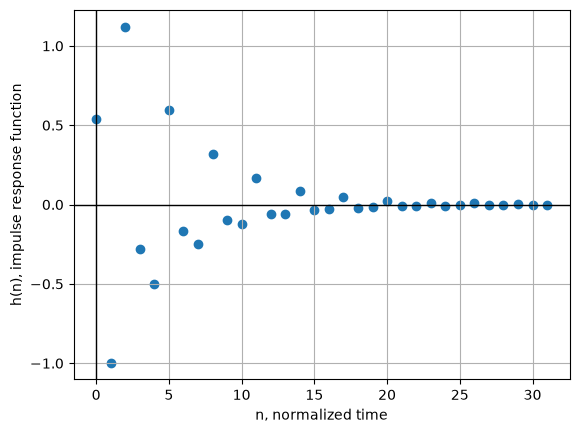

In [134]:
import matplotlib.pyplot as plt

plt.scatter(range(len(impulse_response)), impulse_response)
plt.axhline(0, color='black', linewidth=1)
plt.axvline(0, color='black', linewidth=1)
plt.grid(True)
plt.xlabel("n, normalized time")
plt.ylabel("h(n), impulse response function")

По передаточной функции можно точно восстановить разностное уравнение, а по разностному уравнению можно записать импульсную характеристику системы.

$H(z) = \dfrac{b_0 + b_1z^{-1} + b_2z^{-2}}{1 + a_1z^{-1} + a_2z^{-2}}$ $\Rightarrow$ $y(n) = b_0 x(n) + b_1 x(n-1) + b_2 x(n-2) - a_1 y(n - 1) - a_2 y(n-2)$, а импульсная характеристика по определению реакция системы на цифровой единичный импульс, т.е. $x(n) = u_0(n)$

$$h(n) = b_0 u_0(n) + b_1 u_0(n-1) + b_2 u_0(n-2) - a_1 h(n - 1) - a_2 h(n-2) $$

Так как разностное уравнение задает рекурсивную ЛС, то её импульсная характеристика имеет бесконечную длину (причем из графика видно, что система сходится к нулю со временем и стабилизируется при подаче единичного импульса на вход)

#### 2) Вычислить реакцию $y_1(n)$ по формуле свёртки. В качестве воздействия $x(n)$ длины $N_2$ выбрать дискретный прямоугольный импульс:
   $$
   x(n) =
   \begin{cases}
   1, & 0 \le n < \operatorname{int}(N_2/2),\\
   0, & \operatorname{int}(N_2/2) \le n \le N_2-1.
   \end{cases}
   $$

   где функция $\operatorname{int}(t)$ — округление до ближайшего целого.

   Вывести графики воздействия и реакции.

   Пояснить:
   1. Чему равна длина импульса $x$.
   2. Чему равна длина свёртки аналитически и по графику.
   3. Почему её ограничивают до длины воздействия.


Text(0, 0.5, 'x(n)')

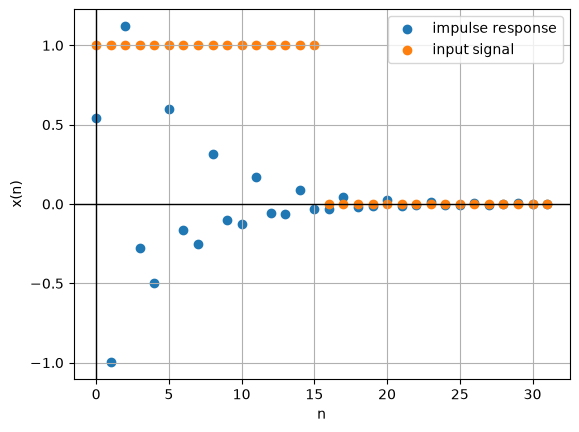

In [133]:
input_length = (n_var % 10) + 30
step_signal = [1 if i < input_length // 2 else 0 for i in range(0, input_length)]

impulse_signal = np.array([1.0] + [0.0] * (input_length-1))
impulse_response = system_response(b, a, impulse_signal, input_length)

plt.scatter(range(input_length), impulse_response, label="impulse response")
plt.scatter(range(input_length), step_signal, label="input signal")
plt.legend()
plt.axhline(0, color='black', linewidth=1)
plt.axvline(0, color='black', linewidth=1)
plt.grid(True)
plt.xlabel("n")
plt.ylabel("x(n)")

Свертка сигналов вычисляется по следующей формуле $$y(n) = x(n) * h(n) = \sum_{m=-\infty}^{+\infty} h(n - m) x(m)$$

и в общем случае входное воздействие x может быть любой длины, в том числе и бесконечной, как и реакция системы y. В нашем случае система задана с нулевыми начальными условиями + длина входного воздействия ограничена $N_2$, но так как $h(n)$ - бесконечная импульсная характеристика, так как система задана рекурсивным разностным уравнением 2 порядка, y(n) ограничивают длиной входного воздействия, иначе сигнал может быть бесконечной длины

Проверка на корректность вычислений:  True


Text(0, 0.5, 'y_1(n)')

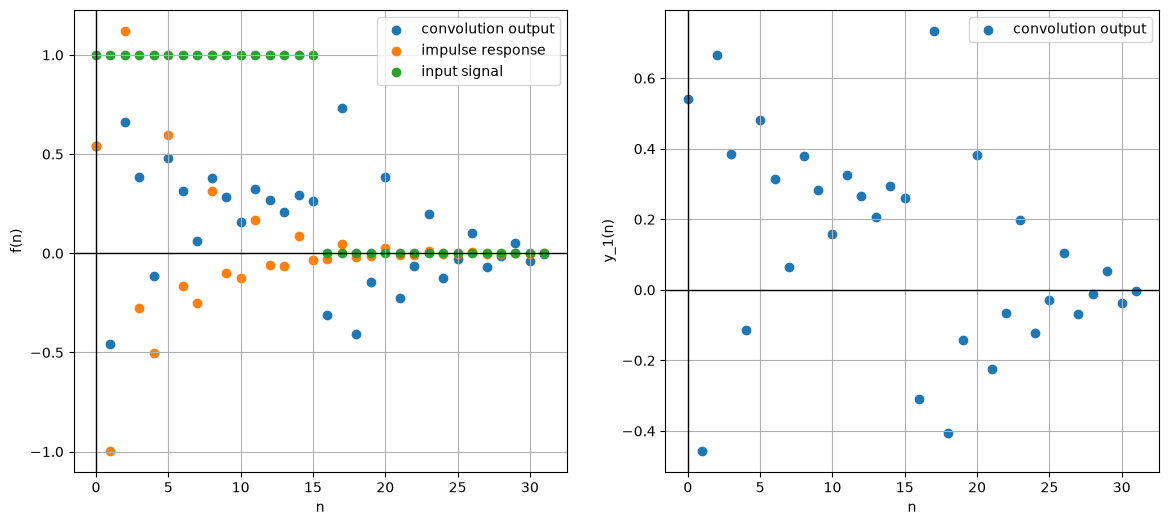

In [125]:
from scipy.signal import lfilter
output_scipy = lfilter(b, a, step_signal)

output_my = []

for i in range(input_length):
    s = 0.0
    for j in range(0, i + 1):
        s += step_signal[j] * impulse_response[i - j]
    output_my.append(s)

print("Проверка на корректность вычислений: ", all(np.isclose(output_scipy, output_my)))

fig, ax = plt.subplots(1, 2, figsize=(14, 6))

ax[0].scatter(range(len(output_my)), output_my, label="convolution output")
ax[0].scatter(range(len(impulse_response)), impulse_response, label="impulse response")
ax[0].scatter(range(len(step_signal)), step_signal, label="input signal")
ax[0].legend()
ax[0].grid(True)
ax[0].axhline(0, color='black', linewidth=1)
ax[0].axvline(0, color='black', linewidth=1)
ax[0].set_xlabel("n")
ax[0].set_ylabel("f(n)")

ax[1].scatter(range(len(output_my)), output_my, label="convolution output")
ax[1].legend()
ax[1].grid(True)
ax[1].axhline(0, color='black', linewidth=1)
ax[1].axvline(0, color='black', linewidth=1)
ax[1].set_xlabel("n")
ax[1].set_ylabel("y_1(n)")

#### 3) Вычислить реакцию $y_2(n)$ по разностному уравнению. Задать воздействие $x(n)$ из п. 2. Вывести графики воздействия и реакции. Сравнить графики реакций $y_1(n)$ и $y_2(n)$. 
Записать разностное уравнение рекурсивного звена 2-го порядка с заданными коэффициентами. Пояснить, чему равны длины воздействия и реакции.

In [126]:
print("Коэффициенты разностного уравнения:", b, a)

Коэффициенты разностного уравнения: [ 0.54     -0.549612  0.648   ] [1.     0.8278 0.652 ]


Разностное уравнение с заданными коэффициентами выглядит следующим образом (коэффициенты округлены до 2 знака после запятой):
$$y(n) = 0.54x(n) - 0.55x(n-1) + 0.65x(n-2) - 0.83y(n - 1) - 0.65y(n-2)$$

Так как заданное разностное уравнение имеет БИХ, то длину реакции ограничиваем длиной воздействия $N_2$ (иначе получили бы бесконечный сигнал)

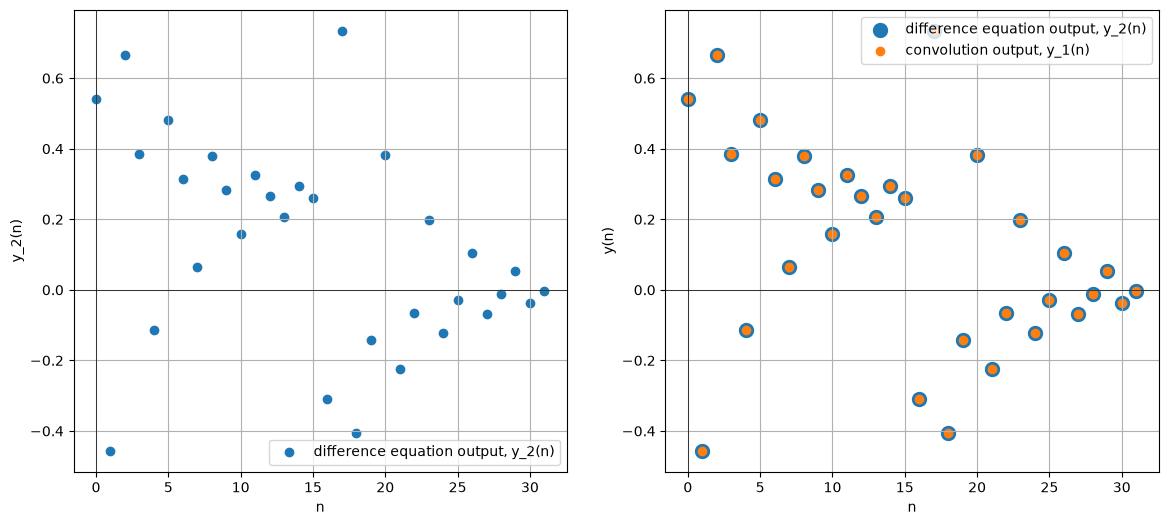

In [127]:
output_signal = system_response(b, a, step_signal, len(step_signal))

fig, ax = plt.subplots(1, 2, figsize=(14, 6))

ax[0].scatter(range(len(output_signal)), output_signal, label="difference equation output, y_2(n)")
ax[0].grid(True)
ax[0].axhline(0, color='black', linewidth=0.5)
ax[0].axvline(0, color='black', linewidth=0.5)
ax[0].set_xlabel("n")
ax[0].set_ylabel("y_2(n)")
ax[0].legend()

ax[1].scatter(range(len(output_signal)), output_signal, label="difference equation output, y_2(n)", linewidths=5)
ax[1].scatter(range(len(output_my)), output_my, label="convolution output, y_1(n)")
ax[1].grid(True)
ax[1].axhline(0, color='black', linewidth=0.5)
ax[1].axvline(0, color='black', linewidth=0.5)
ax[1].set_xlabel("n")
ax[1].set_ylabel("y(n)")
ax[1].legend()

#### 4) Вычислить нули и полюсы передаточной функции. Нули и полюсы представить в алгебраической и показательной формах и пояснить связь между ними. Выразить значение аргумента полюса и нуля относительно $\pi$. Представить передаточную функцию в виде произведения простейших множителей с нулями и полюсами в показательной форме.


In [128]:
from scipy.signal import tf2zpk

zeros, poles, gain = tf2zpk(b, a) # функция вычисляет разложение на простые множители числителя и знаменателя

print(f"Нули ПФ: {zeros}, \nПолюса ПФ: {poles}, \nКоэффициент усиления ПФ: {gain}")

Нули ПФ: [0.5089+0.97006226j 0.5089-0.97006226j], 
Полюса ПФ: [-0.4139+0.6933158j -0.4139-0.6933158j], 
Коэффициент усиления ПФ: 0.5400000214576721


Пакет scipy.signal возвращает значения в алгебраической форме:
$$z_{0_1} = 0.51 + 0.97j; \quad z_{0_2} = 0.51 - 0.97j$$
$$z^{*}_{0} = -0.41 + 0.69j; \quad z^{*}_{1} = -0.41 - 0.69j$$

Показательная форма комплексного числа: $|z|e^{i\phi}=|z|(cos(\phi) + jsin(\phi))$, где $|z| = \sqrt{x^2 + y^2}$ и $\phi = arg{z} = atan2(y, x)$

In [129]:
z0 = zeros[0]
z0_len = np.sqrt(np.real(z0) ** 2 + np.imag(z0) ** 2)
z0_phi = np.rad2deg(np.atan2(np.imag(z0), np.real(z0)))

zstar = poles[0]
zstar_len = np.sqrt(np.real(zstar) ** 2 + np.imag(zstar) ** 2)
zstar_phi = np.rad2deg(np.atan2(np.imag(zstar), np.real(zstar)))

print(f"|z0| = {z0_len}; arg(z0) = {z0_phi}")
print(f"|z*| = {zstar_len}; arg(z*) = {zstar_phi}")

|z0| = 1.095445156097412; arg(z0) = 62.31824493408203
|z*| = 0.8074651956558228; arg(z*) = 120.83661651611328


In [130]:
print(z0_phi / 180.0)
print(zstar_phi / 180.0)

0.34621248
0.67131454


Показательная форма нулей и полюсов:
$$z_{0}^{0} = 1.1e^{62.3^{\circ}j} = 1.1e^{0.35 \pi j}; \quad z_{1}^{0} = 1.1e^{-62.3^{\circ}j} = 1.1e^{-0.35 \pi j}$$
$$z^{*}_{0} = 0.8e^{120.8^{\circ}j} = 0.8e^{0.67 \pi j}; \quad z^{*}_{1} = 0.8e^{-0.67 \pi j}$$

Передаточная функция выраженная через простые множители в показательной форме:

$$H(z) = \dfrac{0.54 - 0.55z^{-1} + 0.65z^{-2}}{1 + 0.83z^{-1} + 0.65z^{-2}} = \dfrac{0.54z^2 - 0.55z + 0.65}{z^2 + 0.83z + 0.65} = K\dfrac{(z - z_{0}^{0})(z - z_{1}^{0})}{(z - z_{0}^{*})(z - z_{1}^{*})} = 0.54\dfrac{(z - 1.1e^{0.35 \pi j})(z - 1.1e^{-0.35 \pi j})}{(z - 0.8e^{0.67 \pi j})(z - 0.8e^{-0.67 \pi j})}$$

#### 5) Изобразить карту нулей и полюсов. Пояснить:
- Является ли рекурсивное звено устойчивым.
- Совпадают ли значения нулей и полюсов с вычисленными в п. 4.

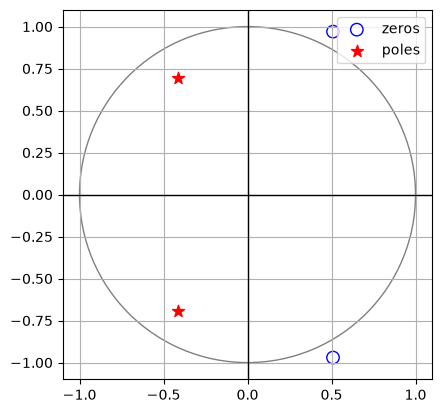

In [143]:
fig, ax = plt.subplots()

ax.scatter(zeros.real, zeros.imag, marker='o', facecolors='none', edgecolors='blue', s=80, label='zeros')

ax.scatter(poles.real, poles.imag, marker='*', color='red', s=80, label='poles')

circle = plt.Circle((0, 0), 1, fill=False, color='gray')
ax.add_patch(circle)
ax.axhline(0, color='black', linewidth=1)
ax.axvline(0, color='black', linewidth=1)

ax.set_aspect('equal')
ax.grid()
ax.legend()
plt.show()

Так как все полюса ПФ простые и находятся внутри единичной окружности, по Теореме об устойчивости, ЛДС - является устойчивой

### 6) Вычислить амплитудно-частотную (АЧХ) и фазочастотную (ФЧХ) характеристики в шкале нормированных частот $\hat{\omega}$ и вывести их графики.

Пояснить:
1. Чему равны границы основной полосы частот.
2. Соответствие между картой нулей и полюсов и видом АЧХ.
3. Какому значению АЧХ соответствует скачок на $\pi$, если он имеется.
4. Какие частотные составляющие воздействия, низкие или высокие, оказались преимущественно подавленными в реакции.


В прошлом задании было вычислено разложение ПФ на простые множители: $$H(z) = K \dfrac{\prod_{i} (z - z_{0}^{(i)})}{\prod_{j} (z - z_{p}^{(j)})}$$

для анализа АЧХ и ФЧХ на вход ПФ подают гармоническое колебание: $H(e^{\hat{\omega}j})$ и изучают модуль и аргумент ПФ.

$$H(e^{\hat{\omega}j}) = K \dfrac{\prod_{i} (e^{\hat{\omega}j} - z_{0}^{(i)})}{\prod_{k} (e^{\hat{\omega}j} - z_{p}^{(k)})}$$

АЧХ: $A(\hat{\omega}) = |H(e^{\hat{\omega}j})| = |K| \dfrac{\prod_{i} |e^{\hat{\omega}j} - z_{0}^{(i)}|}{\prod_{k} |e^{\hat{\omega}j} - z_{p}^{(k)}|}$

ФЧХ: $\phi(\hat{\omega}) = argH(e^{\hat{\omega}j})$

Так как все коэффициент ПФ вещественные числа, а $e^{\hat{\omega}j} = e^{(\hat{\omega} + 2\pi)j} $ - периодическая функция, то для её исследования достаточно рассмотреть $\hat{\omega} \in [0, \pi)$, потому что остальные значения будут повторяться 

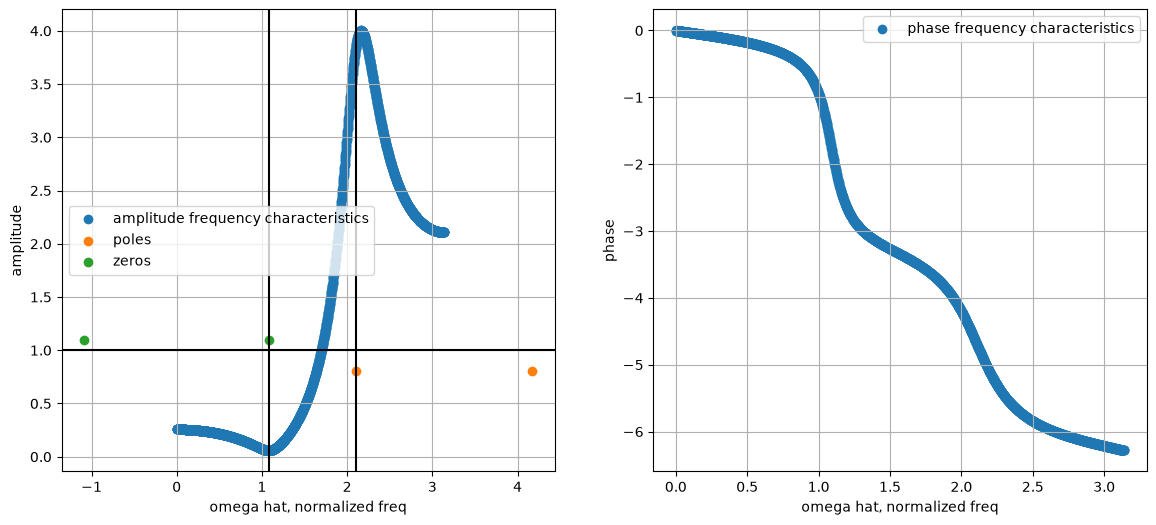

In [201]:
from scipy.signal import freqz

w, h = freqz(b, a, 2048) # подставляет гармонику и вычисляет значения ПФ для w = linspace(0, pi, N) 

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
amp = [np.linalg.norm(h[i]) for i in range(len(h))]
phi = np.unwrap([np.atan2(h[i].imag, h[i].real) for i in range(len(h))])
ax[0].scatter(w, amp, label="amplitude frequency characteristics")
ax[0].axhline(1, c="black")
ax[0].axvline(np.angle(poles[0]), c="black")
ax[0].scatter(np.unwrap(np.angle(poles)), np.abs(poles), label="poles")
ax[0].axvline(np.angle(zeros[0]), c="black")
ax[0].scatter(np.unwrap(np.angle(zeros)), np.abs(zeros), label="zeros")
ax[0].grid(True)
ax[0].set_xlabel("omega hat, normalized freq")
ax[0].set_ylabel("amplitude")
ax[0].legend()

ax[1].scatter(w, phi, label="phase frequency characteristics")
ax[1].grid(True)
ax[1].set_xlabel("omega hat, normalized freq")
ax[1].set_ylabel("phase")
ax[1].legend()

Из левого графика видно, что близи полюсов ПФ наблюдаются локальные максимумы АЧХ, а вблизи нулей наоборот локальные минимумы.
Это объясняется тем, что $|e^{\hat{\omega}j} - z|$ - это на самом деле расстояние до единичной окружности.
Поэтому чем ближе гармоника к нулю ПФ, тем меньше становится амплитуда (потому что эта скобка в числителе).
В случае когда гармоника близка к полюсу ПФ, амплитуда может становится неограниченно большой (потому что эта скобка в знаменателе)

Но из графиков видно, что минимумы и максимумы достигаются не идеально в точках с нулями/полюсами, это потому что вклад вносят сразу два полюса/нуля.

Скачков на pi на графиках нет, оба графика непрерывны на отрезке $[0, \pi)$.

Из графика АЧХ видно, что низкие частоты из интервала $(0, 1.1)$ сильно подавляются системой, а частоты из интервала $(1.8, 2.2)$ наоборот сильно усиливаются. 

#### 7) Вычислить АЧХ и ФЧХ в шкале частот $f$ (Гц) при заданной частоте дискретизации $f_{\text{д}}$ и вывести их графики.

Пояснить:
1. Чему равны границы основной полосы частот.
2. Соответствие частотами $\hat{\omega}$ и $f$.

Перевод из нормализованный шкалы и обратно устроен следующим образом:
$\omega = 2\pi f = \dfrac{2\pi}{T} \Rightarrow \hat{\omega} = \dfrac{\omega}{f_{discrete}}$

Так как раньше $\hat{\omega} \in [0, \pi)$ было, то теперь $f = \dfrac{\hat{\omega}f_{discrete}}{2\pi} \in [0, \dfrac{f_{discrete}}{2}]$

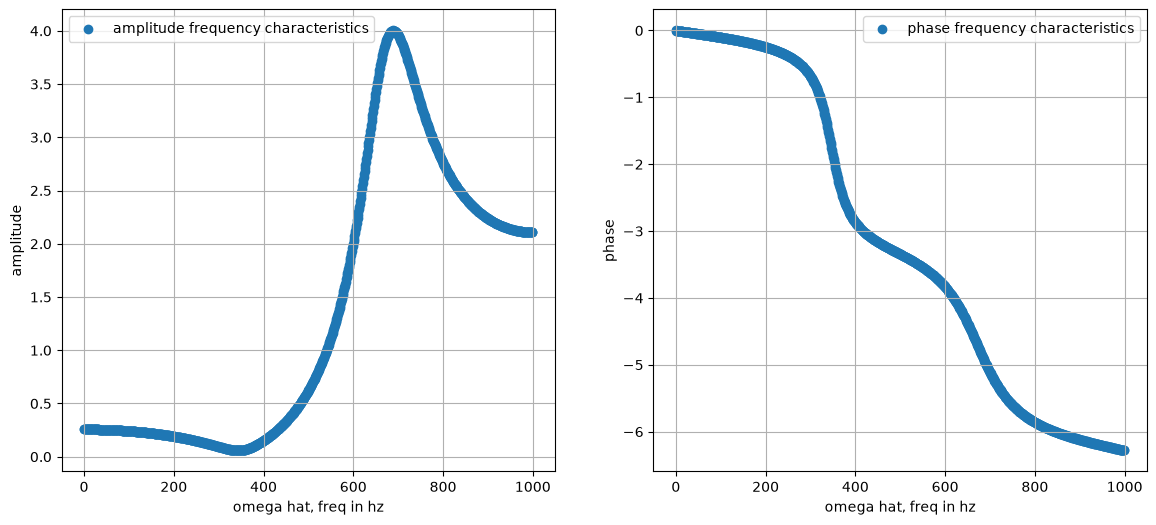

In [206]:
f_discrete = 1_000 * n_var

w, h = freqz(b, a, 1024, fs=f_discrete)

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
amp = [np.linalg.norm(h[i]) for i in range(len(h))]
phi = np.unwrap([np.atan2(h[i].imag, h[i].real) for i in range(len(h))])
ax[0].scatter(w, amp, label="amplitude frequency characteristics")
ax[0].grid(True)
ax[0].set_xlabel("omega hat, freq in hz")
ax[0].set_ylabel("amplitude")
ax[0].legend()

ax[1].scatter(w, phi, label="phase frequency characteristics")
ax[1].grid(True)
ax[1].set_xlabel("omega hat, freq in hz")
ax[1].set_ylabel("phase")
ax[1].legend()

### Часть 2

#### 1) Вычислить амплитудный и фазовый спектры периодической последовательности $x(n)$ с периодом $N$:

   $$
   x(nT) = A_1 \cos(2\pi f_1 nT + \pi/4) + A_2 \cos(2\pi f_2 nT + \pi/8)
   $$

   Вывести графики последовательности $x(n)$ на периоде $N$ в шкале дискретного и дискретного нормированного времени.


#### 2) Вычислить ОДПФ от ДПФ последовательности $x(n)$ и вывести график полученной последовательности в шкале дискретного нормированного времени.


#### 3) Вычислить амплитудный и фазовый спектры последовательности $x(n)$ и вывести их графики в шкалах дискретных нормированных и абсолютных частот.

   Пояснить:
   1. Связь дискретного нормированного времени с дискретным временем.
   2. Связь частоты $f$ (Гц) с дискретной нормированной частотой.
   3. Вид амплитудного и фазового спектров.


#### 4) Вычислить ДПФ конечной последовательности $x(n)$ длины $N$. Вывести графики в шкале дискретных нормированных частот модуля ДПФ конечной последовательности и амплитудного спектра периодической последовательности.

   Пояснить связь модуля ДПФ конечной последовательности с амплитудным спектром периодической последовательности.


#### 5) Восстановить периодический аналоговый сигнал $x(t)$ по отсчётам ДПФ $X(k)$ периодической последовательности $x(n)$. Для вычисления значений сигнала $x(t)$ использовать формулу:

   $$
   x(t) = \frac{1}{N} \sum_{k=-N/2}^{N/2-1} X_a(k) \exp\left(j\frac{2\pi}{NT}kt\right),
   $$

   где отсчёты $X_a(k)$ связаны с отсчётами ДПФ $X(k)$ соотношением:

   $$
   X_a(k) =
   \begin{cases}
   X(N+k), & -N/2 \le k \le -1,\\
   X(k), & 0 \le k \le N/2-1.
   \end{cases}
   $$

   Задавая значения времени $t$ на интервале $t \in [0; (N-1)T]$ с шагом $\Delta t = 0.25T$, вывести графики:

   1. Периодической последовательности $x(n)$ и модуля её ДПФ.
   2. Восстановленного аналогового сигнала $x(t)$ и его амплитудного спектра.
   3. Исходного аналогового сигнала $x(t) = x(nT)|_{nT=t}$.


#### 6) Исходя из результатов п. 5, объяснить:

   1. Связь модуля ДПФ последовательности со спектром аналогового сигнала.
   2. Результат визуального сравнения восстановленного и исходного сигналов.

#### 7) Проверить равенство Парсеваля. Пояснить его смысл.

Также можно вставлять таблицы. [Удобный сайт для создания Markdown-таблиц.](https://www.tablesgenerator.com/markdown_tables "Markdown Tables generator")

Не забывайте проанализировать полученные результаты.

## Выводы

Общий вывод по проделанной работе.